In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os
from datetime import datetime
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout

In [9]:
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Stock Price Prediction/all_stocks_5yr.csv',
                   delimiter=',',
                   on_bad_lines='skip')
print(data.shape)
print(data.head())
print(data.info())

(619040, 7)
         date   open   high    low  close    volume Name
0  2013-02-08  15.07  15.12  14.63  14.75   8407500  AAL
1  2013-02-11  14.89  15.01  14.26  14.46   8882000  AAL
2  2013-02-12  14.45  14.51  14.10  14.27   8126000  AAL
3  2013-02-13  14.30  14.94  14.25  14.66  10259500  AAL
4  2013-02-14  14.94  14.96  13.16  13.99  31879900  AAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB
None


In [14]:
data['date'] = pd.to_datetime(data['date'])
data.info

<bound method DataFrame.info of              date   open   high    low  close    volume Name       data
0      2013-02-08  15.07  15.12  14.63  14.75   8407500  AAL 2013-02-08
1      2013-02-11  14.89  15.01  14.26  14.46   8882000  AAL 2013-02-11
2      2013-02-12  14.45  14.51  14.10  14.27   8126000  AAL 2013-02-12
3      2013-02-13  14.30  14.94  14.25  14.66  10259500  AAL 2013-02-13
4      2013-02-14  14.94  14.96  13.16  13.99  31879900  AAL 2013-02-14
...           ...    ...    ...    ...    ...       ...  ...        ...
619035 2018-02-01  76.84  78.27  76.69  77.82   2982259  ZTS 2018-02-01
619036 2018-02-02  77.53  78.12  76.73  76.78   2595187  ZTS 2018-02-02
619037 2018-02-05  76.64  76.92  73.18  73.83   2962031  ZTS 2018-02-05
619038 2018-02-06  72.74  74.56  72.13  73.27   4924323  ZTS 2018-02-06
619039 2018-02-07  72.70  75.00  72.69  73.86   4534912  ZTS 2018-02-07

[619040 rows x 8 columns]>

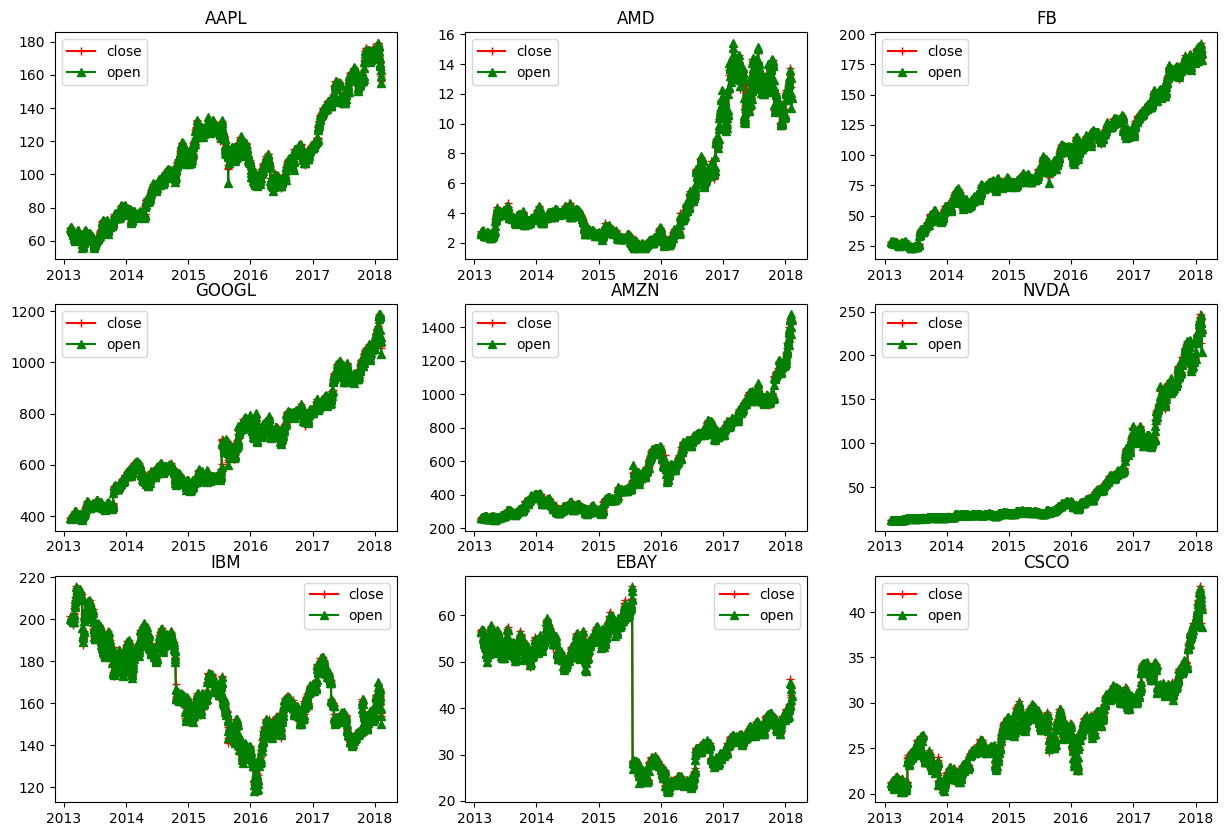

In [11]:
companies = ['AAPL', 'AMD', 'FB', 'GOOGL', 'AMZN', 'NVDA', 'IBM', 'EBAY', 'CSCO']

plt.figure(figsize=(15, 10))
for index, company in enumerate(companies):
    plt.subplot(3, 3, index + 1)
    c = data[data['Name'] == company]
    plt.plot(c['data'], c['close'], c='r', label='close', marker='+')
    plt.plot(c['data'], c['open'], c='g', label='open', marker='^')
    plt.title(company)
    plt.legend()

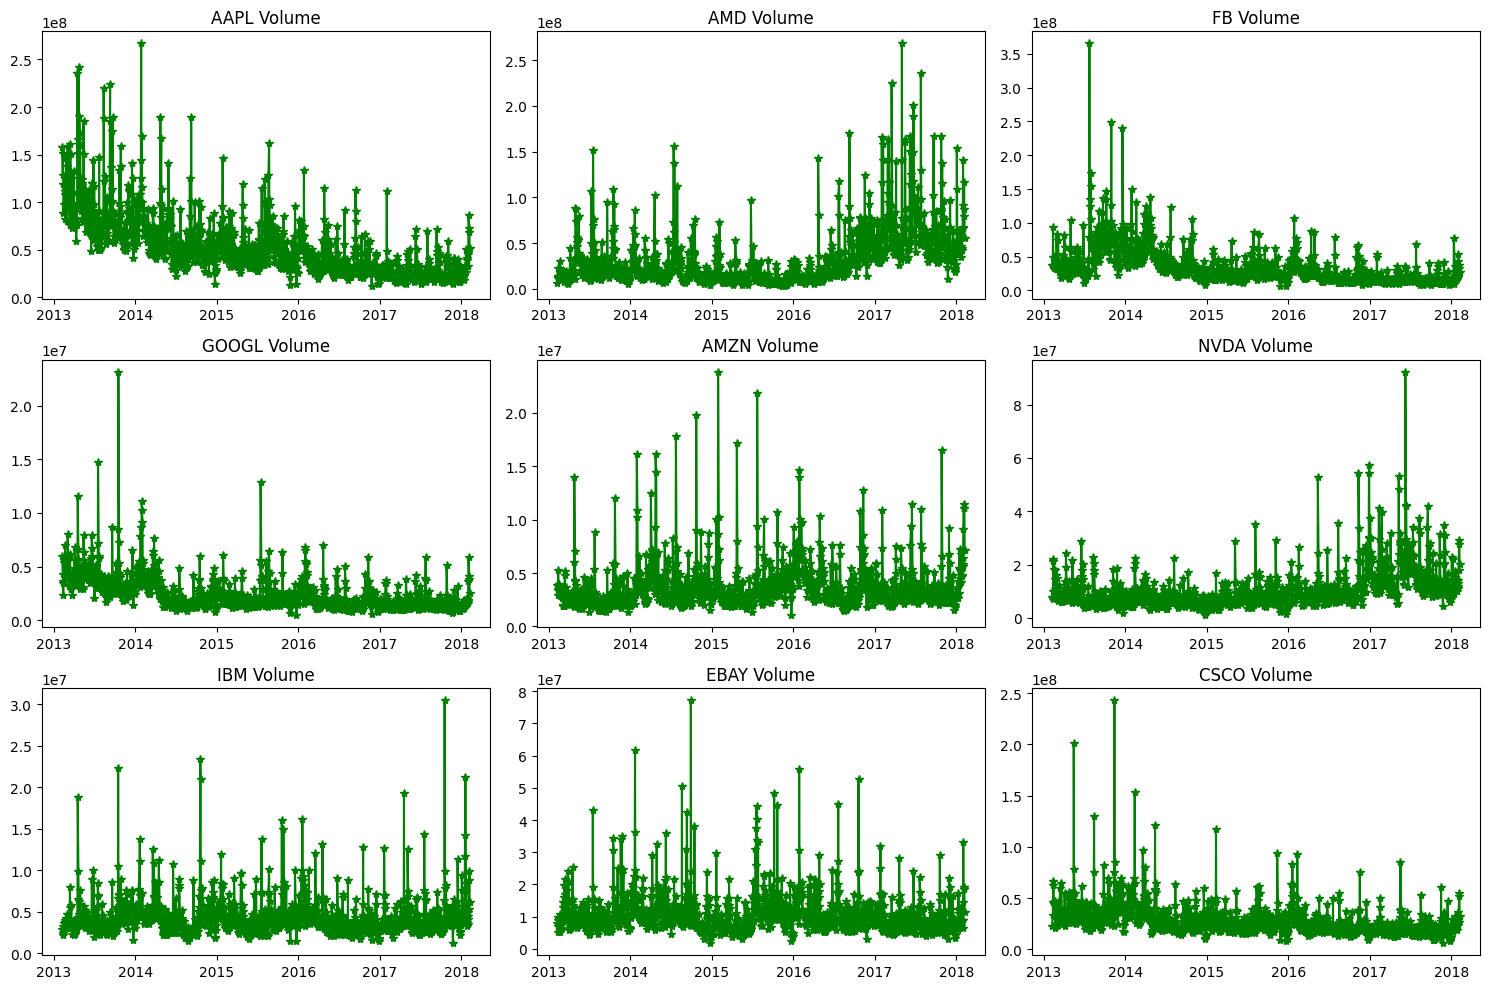

In [16]:
plt.figure(figsize=(15, 10))
for index, company in enumerate(companies):
    plt.subplot(3, 3, index + 1)
    com = data[data['Name'] == company]
    plt.plot(com['date'], com['volume'], c='green', marker='*')
    plt.title(f"{company} Volume")
    plt.tight_layout()

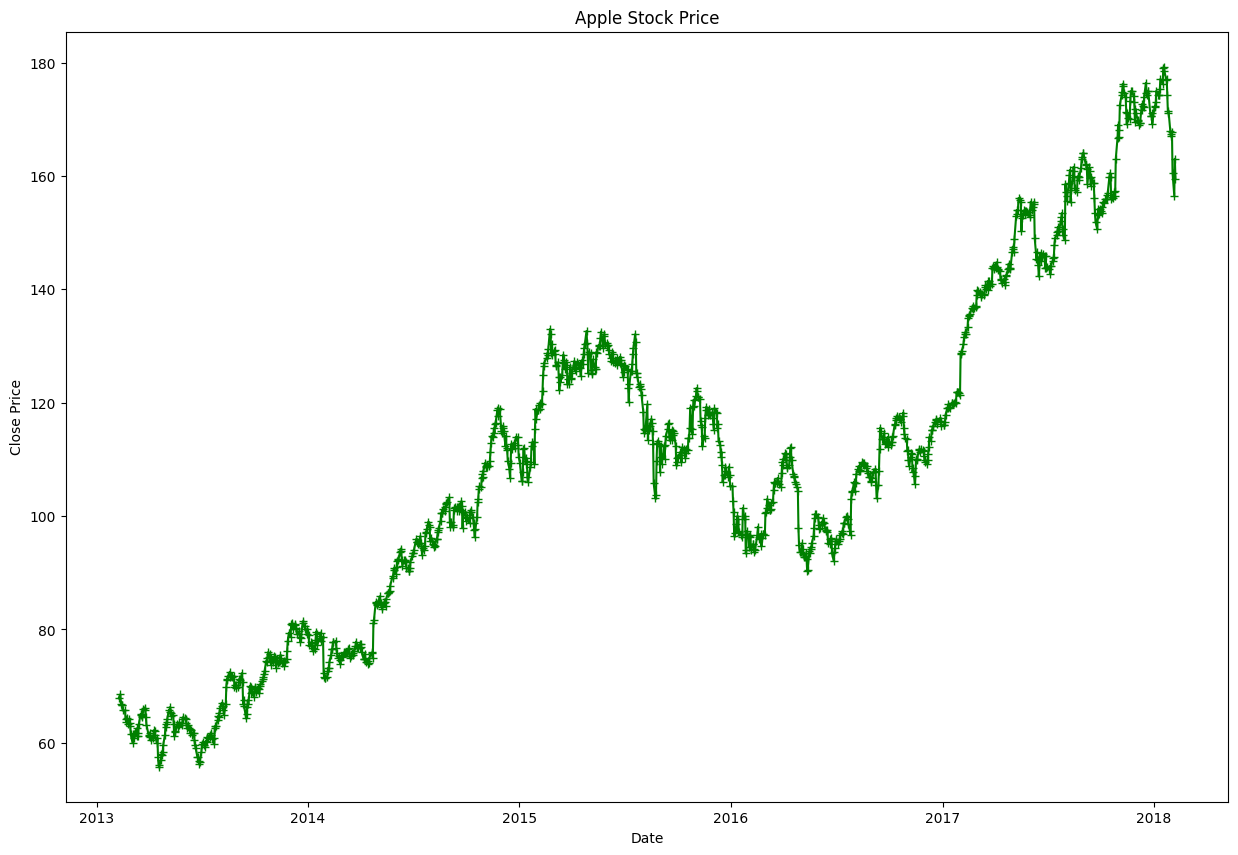

In [17]:
apple_stock_data = data[data['Name'] == 'AAPL']
pred_range = apple_stock_data.loc[(apple_stock_data['date'] > datetime(2013, 1, 1)) & (apple_stock_data['date'] < datetime(2018, 1, 1))]
plt.figure(figsize=(15, 10))
plt.plot(apple_stock_data['date'], apple_stock_data['close'], c='green', label='close', marker='+')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.title('Apple Stock Price')
plt.show()


In [29]:
closed_data = apple_stock_data.filter(['close'])
dataset = closed_data.values
training_data_len = int(np.ceil(len(dataset) * .95))
print(training_data_len)

1197


In [32]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)
train_data = scaled_data[0:int(training_data_len), :]

x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i - 60:i, 0])
    y_train.append(train_data[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

In [36]:
model = Sequential()
model.add(LSTM(64, return_sequences=True, input_shape=(x_train.shape[1], 1)))
model.add(LSTM(64))
model.add(Dense(32))
model.add(Dropout(0.5))
model.add(Dense(1))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,033 (203.25 KB)

 Trainable params: 52,033 (203.25 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(optimizer='adam', loss='mean_squared_error')
history = model.fit(x_train, y_train, epochs=10)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - loss: 0.0286
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0108
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - loss: 0.0082
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0075
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0078
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0068
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.0075
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - loss: 0.0068
Epoch 9/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0073
Epoch 10/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0058


In [39]:
test_data = scaled_data[training_data_len - 60:, :]
x_test = []
y_test = dataset[training_data_len:, :]

for i in range(60, len(test_data)):
    x_test.append(test_data[i - 60:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

mse = mean_squared_error(y_test, predictions)
print("Mean Squared Error:", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Mean Squared Error: 18.39773352852234
Root Mean Squared Error: 4.289257922825619


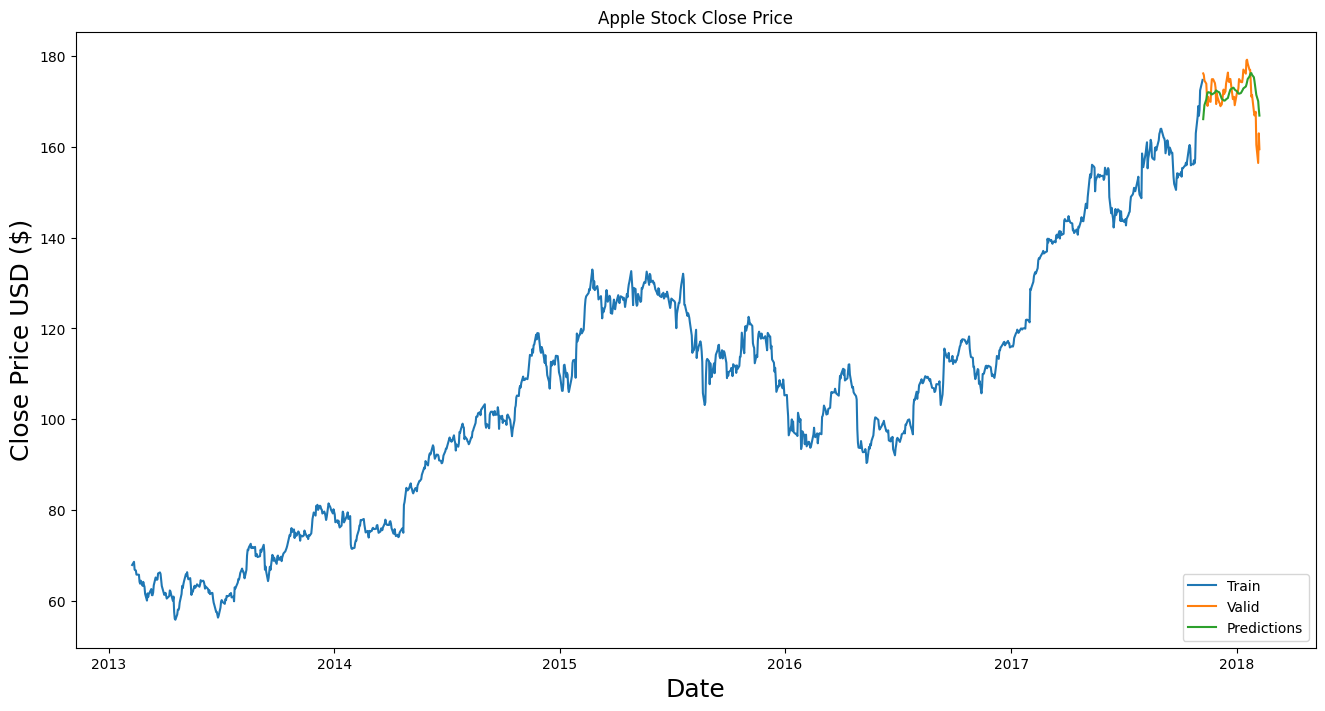

In [44]:
train = apple_stock_data[:training_data_len]
valid = apple_stock_data[training_data_len:].copy()
valid['Predictions'] = predictions

plt.figure(figsize=(16, 8))
plt.title('Apple Stock Close Price')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train['date'], train['close'])
plt.plot(valid['date'], valid[['close', 'Predictions']])
plt.legend(['Train', 'Valid', 'Predictions'], loc='lower right')
plt.show()

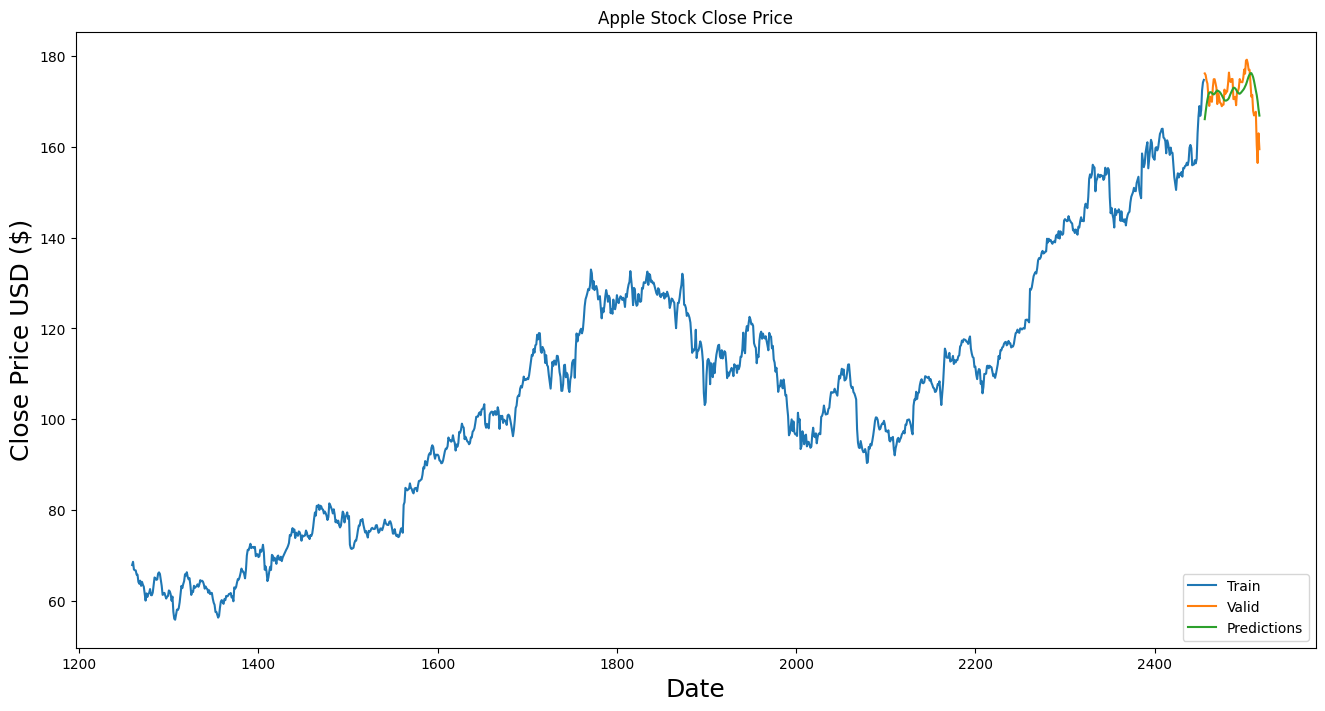

In [43]:
train = closed_data[:training_data_len]
valid = closed_data[training_data_len:].copy()
valid['Predictions'] = predictions

plt.figure(figsize=(16, 8))
plt.title('Apple Stock Close Price')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train['close'])
plt.plot(valid[['close', 'Predictions']])
plt.legend(['Train', 'Valid', 'Predictions'], loc='lower right')
plt.show()